In [50]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.RadialExperiment import RadialDevice, RadialPlots, RadialSummaries
import numpy as np
import matplotlib.pyplot as plt
import pickle

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM041'
record_date = '251128'
experiment_name = 'tiling_3_120um'

data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
summ_name = f'{record_date}_{mouse_name}_{experiment_name}_summaries.pkl'
summ_dir = os.path.join(data_dir, summ_name)

try:
    with open(summ_dir, 'rb') as f:
        summ = pickle.load(f)
        print(f"File {summ_dir} imported.")
except FileNotFoundError:
    print(f"The file {summ_dir} does not exist.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
File D:\data-distance-coding-project\processed-data\251128_SAM041_tiling_3_120um\251128_SAM041_tiling_3_120um_summaries.pkl imported.


In [75]:
R = summ.R

# Get reliable cells from radial_stats
reliable_cells = summ.radial_stats[
    (summ.radial_stats['responsive_corr'] >= 0.95) &
    (summ.radial_stats['responsive_visually'] == True) &
    (summ.radial_stats['responsive_control'] == False) &
    (summ.radial_stats['responsive_control_higher'] == False)
]['cell_id'].values

reliable_cells = [int(cell) for cell in reliable_cells]
print(f"Number of reliable cells: {len(reliable_cells)}")
print(f"Reliable cell IDs: {sorted(reliable_cells)}")

Number of reliable cells: 249
Reliable cell IDs: [66, 79, 83, 84, 90, 107, 110, 112, 122, 123, 124, 125, 131, 141, 149, 150, 160, 161, 163, 165, 176, 184, 186, 191, 211, 222, 223, 228, 231, 249, 262, 263, 264, 265, 270, 271, 277, 278, 282, 287, 307, 308, 309, 310, 326, 333, 338, 341, 351, 357, 360, 362, 363, 364, 365, 369, 373, 374, 378, 387, 410, 412, 422, 425, 429, 435, 445, 449, 452, 453, 463, 468, 472, 474, 475, 481, 484, 489, 500, 510, 518, 519, 529, 534, 546, 547, 553, 554, 560, 562, 571, 576, 579, 580, 594, 595, 605, 607, 612, 619, 620, 629, 647, 653, 661, 662, 671, 675, 688, 693, 697, 698, 708, 734, 735, 747, 754, 760, 792, 798, 805, 808, 814, 860, 865, 869, 877, 898, 902, 903, 908, 913, 920, 931, 936, 959, 960, 963, 969, 1035, 1065, 1071, 1073, 1082, 1092, 1094, 1111, 1114, 1120, 1137, 1141, 1145, 1152, 1185, 1186, 1216, 1217, 1221, 1234, 1236, 1241, 1272, 1316, 1319, 1333, 1341, 1348, 1360, 1364, 1377, 1397, 1423, 1439, 1440, 1444, 1468, 1481, 1483, 1487, 1491, 1494, 1507, 15

In [56]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [55]:
def obtain_neural_data(reliable_cells, distance=None, monocular=False):

    """
    Obtain the neural data for a given cell and monocular/binocular condition
    Goal is to obtain a matrix of shape (n_trials, n_positions, n_neurons)
    
    Returns: X
    """

    all_traces_neuron = R.get_all_traces(cell=123, distance=distance, monocular=monocular, mean_trace = False)

    n_trials = all_traces_neuron.shape[0]
    n_positions = all_traces_neuron.shape[1]
    n_neurons = len(reliable_cells)

    print(f"Trials: {n_trials}, Positions: {n_positions}, Neurons: {n_neurons}")

    X = np.zeros((n_trials, n_positions, n_neurons))

    for i, cell in enumerate(reliable_cells):

        x_cell = R.get_all_traces(cell, distance=distance, monocular=monocular, mean_trace = False)
        X[:, :, i] = x_cell

    distances = np.squeeze(R.distance_sequence)

    condition_trials = R.get_condition_trials(monocular=False, distance=None)
    distances = distances[condition_trials]

    return X, distances

positions = np.squeeze(R.angle_range)

In [ ]:
def decode_position(X, positions):
    """
    X: (n_trials, n_positions, n_cells) - neural activity
    positions: (n_positions,) - stimulus positions
    
    Returns: predictions, actual, r2, mae
    """
    n_trials, n_positions, n_cells = X.shape
    
    # Flatten: each sample is one (trial, position) pair
    X_flat = X.reshape(-1, n_cells)
    y = np.tile(positions, n_trials)
    trial_ids = np.repeat(np.arange(n_trials), n_positions)
    
    # Leave-one-trial-out cross-validation
    predictions = np.zeros_like(y)
    logo = LeaveOneGroupOut()
    
    for train_idx, test_idx in logo.split(X_flat, y, groups=trial_ids):
        model = Ridge(alpha=1.0)
        model.fit(X_flat[train_idx], y[train_idx])
        predictions[test_idx] = model.predict(X_flat[test_idx])
    
    # Metrics
    r2 = 1 - np.sum((y - predictions)**2) / np.sum((y - y.mean())**2)
    mae = np.mean(np.abs(y - predictions))
    
    return predictions, y, r2, mae

def plot_results(predictions, actual, r2, mae):
    """Simple diagnostic plot."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # Actual vs predicted
    axes[0].scatter(actual, predictions, alpha=0.3, s=10)
    axes[0].plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'r--')
    axes[0].set_xlabel('Actual position')
    axes[0].set_ylabel('Decoded position')
    axes[0].set_title(f'R² = {r2:.3f}, MAE = {mae:.2f}')
    
    # Error by position
    positions_unique = np.unique(actual)
    mean_error = [np.mean(predictions[actual == p] - p) for p in positions_unique]
    axes[1].plot(positions_unique, mean_error, 'o-')
    axes[1].axhline(0, color='gray', linestyle='--')
    axes[1].set_xlabel('Actual position')
    axes[1].set_ylabel('Mean decoding error')
    axes[1].set_title('Bias by position')
    
    plt.tight_layout()
    plt.savefig('decoder_results.png', dpi=150)
    plt.show()

Trials: 48, Positions: 59, Neurons: 249
Trials: 48, Positions: 59, Neurons: 249
Trials: 24, Positions: 59, Neurons: 249


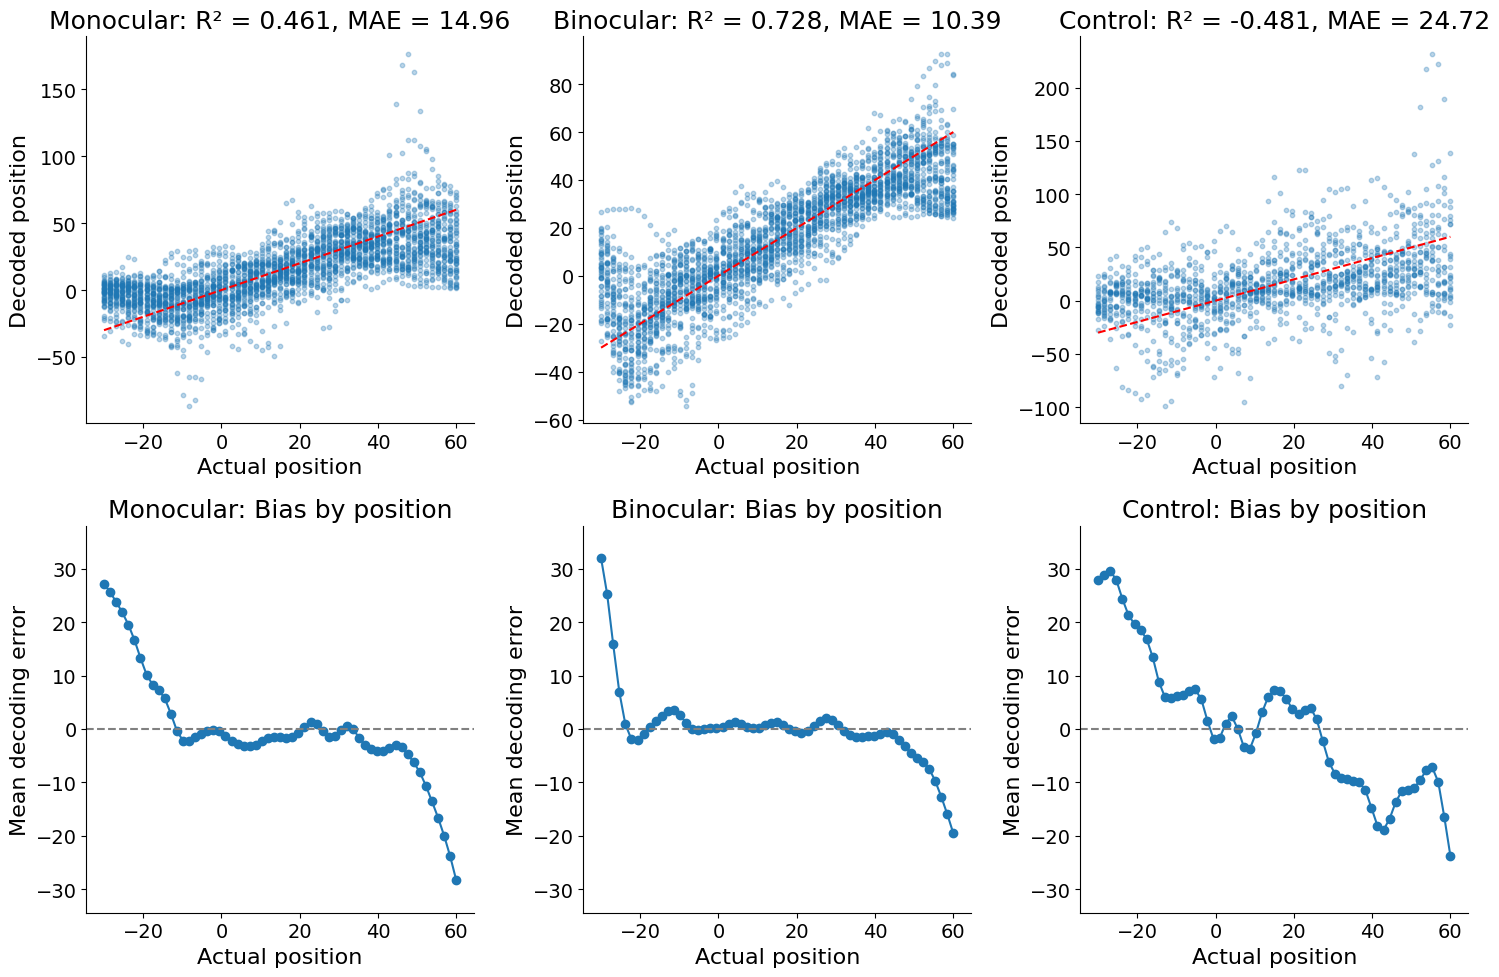

Monocular - R² = 0.461, MAE = 14.96
Binocular - R² = 0.728, MAE = 10.39
Control - R² = -0.481, MAE = 24.72


In [76]:
# Decode
X_monocular = obtain_neural_data(reliable_cells, distance=None, monocular=True)[0]
X_binocular = obtain_neural_data(reliable_cells, distance=None, monocular=False)[0]
X_control = obtain_neural_data(reliable_cells, distance=4, monocular=None)[0]

# Create 2x3 subplot for all conditions (rows = plot types, columns = conditions)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Monocular condition (column 0)
predictions_mono, actual_mono, r2_mono, mae_mono = decode_position(X_monocular, positions)
axes[0, 0].scatter(actual_mono, predictions_mono, alpha=0.3, s=10)
axes[0, 0].plot([actual_mono.min(), actual_mono.max()], [actual_mono.min(), actual_mono.max()], 'r--')
axes[0, 0].set_xlabel('Actual position')
axes[0, 0].set_ylabel('Decoded position')
axes[0, 0].set_title(f'Monocular: R² = {r2_mono:.3f}, MAE = {mae_mono:.2f}')

positions_unique_mono = np.unique(actual_mono)
mean_error_mono = [np.mean(predictions_mono[actual_mono == p] - p) for p in positions_unique_mono]

# Binocular condition (column 1)
predictions_bino, actual_bino, r2_bino, mae_bino = decode_position(X_binocular, positions)
axes[0, 1].scatter(actual_bino, predictions_bino, alpha=0.3, s=10)
axes[0, 1].plot([actual_bino.min(), actual_bino.max()], [actual_bino.min(), actual_bino.max()], 'r--')
axes[0, 1].set_xlabel('Actual position')
axes[0, 1].set_ylabel('Decoded position')
axes[0, 1].set_title(f'Binocular: R² = {r2_bino:.3f}, MAE = {mae_bino:.2f}')

positions_unique_bino = np.unique(actual_bino)
mean_error_bino = [np.mean(predictions_bino[actual_bino == p] - p) for p in positions_unique_bino]

# Control condition (column 2)
predictions_ctrl, actual_ctrl, r2_ctrl, mae_ctrl = decode_position(X_control, positions)
axes[0, 2].scatter(actual_ctrl, predictions_ctrl, alpha=0.3, s=10)
axes[0, 2].plot([actual_ctrl.min(), actual_ctrl.max()], [actual_ctrl.min(), actual_ctrl.max()], 'r--')
axes[0, 2].set_xlabel('Actual position')
axes[0, 2].set_ylabel('Decoded position')
axes[0, 2].set_title(f'Control: R² = {r2_ctrl:.3f}, MAE = {mae_ctrl:.2f}')

positions_unique_ctrl = np.unique(actual_ctrl)
mean_error_ctrl = [np.mean(predictions_ctrl[actual_ctrl == p] - p) for p in positions_unique_ctrl]

# Find common y-axis limits for bias plots
all_errors = mean_error_mono + mean_error_bino + mean_error_ctrl
y_min = min(all_errors)
y_max = max(all_errors)
y_margin = (y_max - y_min) * 0.1
y_lim = [y_min - y_margin, y_max + y_margin]

# Plot bias with shared y-axis
axes[1, 0].plot(positions_unique_mono, mean_error_mono, 'o-')
axes[1, 0].axhline(0, color='gray', linestyle='--')
axes[1, 0].set_xlabel('Actual position')
axes[1, 0].set_ylabel('Mean decoding error')
axes[1, 0].set_title('Monocular: Bias by position')
axes[1, 0].set_ylim(y_lim)

axes[1, 1].plot(positions_unique_bino, mean_error_bino, 'o-')
axes[1, 1].axhline(0, color='gray', linestyle='--')
axes[1, 1].set_xlabel('Actual position')
axes[1, 1].set_ylabel('Mean decoding error')
axes[1, 1].set_title('Binocular: Bias by position')
axes[1, 1].set_ylim(y_lim)

axes[1, 2].plot(positions_unique_ctrl, mean_error_ctrl, 'o-')
axes[1, 2].axhline(0, color='gray', linestyle='--')
axes[1, 2].set_xlabel('Actual position')
axes[1, 2].set_ylabel('Mean decoding error')
axes[1, 2].set_title('Control: Bias by position')
axes[1, 2].set_ylim(y_lim)

plt.tight_layout()
plt.show()

print(f'Monocular - R² = {r2_mono:.3f}, MAE = {mae_mono:.2f}')
print(f'Binocular - R² = {r2_bino:.3f}, MAE = {mae_bino:.2f}')
print(f'Control - R² = {r2_ctrl:.3f}, MAE = {mae_ctrl:.2f}')

In [58]:
positions = np.squeeze(R.angle_range)
distances = np.squeeze(R.distance_sequence)

condition_trials = R.get_condition_trials(monocular=False, distance=None)
distances = distances[condition_trials]

def decode_joint(X, positions, distances):
    """
    X: (n_trials, n_positions, n_cells)
    positions: (n_positions,)
    distances: (n_trials,) — one distance per trial
    """
    n_trials, n_positions, n_cells = X.shape
    
    X_flat = X.reshape(-1, n_cells)
    y_pos = np.tile(positions, n_trials)
    y_dist = np.repeat(distances, n_positions)  # repeat distance for each position in trial
    y = np.column_stack([y_pos, y_dist])  # (n_samples, 2)
    
    trial_ids = np.repeat(np.arange(n_trials), n_positions)
    
    predictions = np.zeros_like(y)
    logo = LeaveOneGroupOut()
    
    for train_idx, test_idx in logo.split(X_flat, y, groups=trial_ids):
        model = Ridge(alpha=1.0)
        model.fit(X_flat[train_idx], y[train_idx])
        predictions[test_idx] = model.predict(X_flat[test_idx])
    
    # Separate metrics
    r2_pos = 1 - np.sum((y[:, 0] - predictions[:, 0])**2) / np.sum((y[:, 0] - y[:, 0].mean())**2)
    r2_dist = 1 - np.sum((y[:, 1] - predictions[:, 1])**2) / np.sum((y[:, 1] - y[:, 1].mean())**2)
    
    return predictions, y, r2_pos, r2_dist

In [7]:
def plot_error_heatmaps(predictions, actual, positions, distances):
    """
    Side-by-side heatmaps: position error and distance error.
    
    predictions: (n_samples, 2) — [pos, dist]
    actual: (n_samples, 2) — [pos, dist]
    """
    pos_bins = np.unique(actual[:, 0])
    dist_bins = np.unique(actual[:, 1])
    
    pos_error = np.abs(predictions[:, 0] - actual[:, 0])
    dist_error = np.abs(predictions[:, 1] - actual[:, 1])
    
    # Build heatmaps
    pos_error_map = np.full((len(dist_bins), len(pos_bins)), np.nan)
    dist_error_map = np.full((len(dist_bins), len(pos_bins)), np.nan)
    
    for i, d in enumerate(dist_bins):
        for j, p in enumerate(pos_bins):
            mask = (actual[:, 0] == p) & (actual[:, 1] == d)
            if mask.sum() > 0:
                pos_error_map[i, j] = pos_error[mask].mean()
                dist_error_map[i, j] = dist_error[mask].mean()
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    im0 = axes[0].imshow(pos_error_map, aspect='auto', origin='lower', cmap='viridis',
                          extent=[pos_bins.min(), pos_bins.max(), dist_bins.min(), dist_bins.max()])
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('Distance')
    axes[0].set_title('Position decoding error (MAE)')
    plt.colorbar(im0, ax=axes[0])
    
    im1 = axes[1].imshow(dist_error_map, aspect='auto', origin='lower', cmap='viridis',
                          extent=[pos_bins.min(), pos_bins.max(), dist_bins.min(), dist_bins.max()])
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('Distance')
    axes[1].set_title('Distance decoding error (MAE)')
    plt.colorbar(im1, ax=axes[1])
    
    plt.tight_layout()
    plt.show()



In [59]:
def plot_error_by_position(predictions, actual, positions):
    """
    Distance decoding error as a function of position.
    """
    pos_bins = np.unique(actual[:, 0])
    dist_error = np.abs(predictions[:, 1] - actual[:, 1])
    
    mean_error = [dist_error[actual[:, 0] == p].mean() for p in pos_bins]
    sem_error = [dist_error[actual[:, 0] == p].std() / np.sqrt((actual[:, 0] == p).sum()) for p in pos_bins]
    
    plt.figure(figsize=(8, 4))
    plt.errorbar(pos_bins, mean_error, yerr=sem_error, fmt='o-', capsize=2)
    plt.xlabel('Position')
    plt.ylabel('Distance decoding error (MAE)')
    plt.axhline(np.mean(dist_error), color='gray', linestyle='--', label='Overall MAE')
    plt.legend()
    plt.tight_layout()
    plt.show()


In [60]:
def plot_errors_by_position(results_dict):
    """
    Plot decoding error and bias by position for multiple conditions.
    
    results_dict: {
        'Binocular': (predictions, actual),
        'Monocular': (predictions, actual),
        ...
    }
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    for label, (predictions, actual) in results_dict.items():
        pos_bins = np.unique(actual[:, 0])
        
        pos_error = np.abs(predictions[:, 0] - actual[:, 0])
        dist_error = np.abs(predictions[:, 1] - actual[:, 1])
        pos_bias = predictions[:, 0] - actual[:, 0]
        dist_bias = predictions[:, 1] - actual[:, 1]
        
        mean_pos_err = [pos_error[actual[:, 0] == p].mean() for p in pos_bins]
        mean_dist_err = [dist_error[actual[:, 0] == p].mean() for p in pos_bins]

        axes[0].plot(pos_bins, mean_pos_err, 'o-', label=label, markersize=3)
        axes[1].plot(pos_bins, mean_dist_err, 'o-', label=label, markersize=3)
    
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('MAE')
    axes[0].set_title('Position decoding error')
    axes[0].legend()
    
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('MAE')
    axes[1].set_title('Distance decoding error')
    axes[1].legend()

    
    plt.tight_layout()
    plt.show()

In [77]:
R = summ.R

# Get reliable cells from radial_stats
reliable_cells = summ.radial_stats[
    (summ.radial_stats['responsive_corr'] >= 0.9) &
    (summ.radial_stats['responsive_visually'] == True) &
    (summ.radial_stats['responsive_control'] == False) &
    (summ.radial_stats['responsive_control_higher'] == False)
]['cell_id'].values

reliable_cells = [int(cell) for cell in reliable_cells]
print(f"Number of reliable cells: {len(reliable_cells)}")
print(f"Reliable cell IDs: {sorted(reliable_cells)}")

Number of reliable cells: 490
Reliable cell IDs: [9, 21, 42, 46, 49, 56, 58, 62, 66, 79, 83, 84, 86, 90, 107, 110, 112, 115, 119, 122, 123, 124, 125, 131, 137, 139, 140, 141, 145, 149, 150, 156, 160, 161, 163, 165, 174, 176, 178, 184, 186, 187, 191, 192, 201, 211, 222, 223, 225, 226, 228, 230, 231, 242, 249, 256, 260, 261, 262, 263, 264, 265, 267, 270, 271, 272, 277, 278, 282, 287, 294, 301, 306, 307, 308, 309, 310, 320, 324, 326, 333, 336, 338, 341, 345, 351, 352, 357, 359, 360, 362, 363, 364, 365, 368, 369, 373, 374, 378, 387, 389, 403, 410, 411, 412, 415, 422, 425, 429, 433, 435, 444, 445, 449, 452, 453, 463, 468, 469, 472, 474, 475, 481, 484, 489, 490, 495, 496, 500, 510, 518, 519, 529, 533, 534, 541, 544, 546, 547, 548, 553, 554, 560, 562, 570, 571, 576, 579, 580, 594, 595, 597, 600, 603, 605, 607, 612, 619, 620, 622, 624, 629, 637, 647, 650, 653, 661, 662, 671, 675, 688, 693, 696, 697, 698, 706, 708, 724, 734, 735, 736, 737, 747, 754, 760, 774, 789, 792, 798, 802, 805, 808, 812, 

Trials: 48, Positions: 59, Neurons: 490
Trials: 48, Positions: 59, Neurons: 490


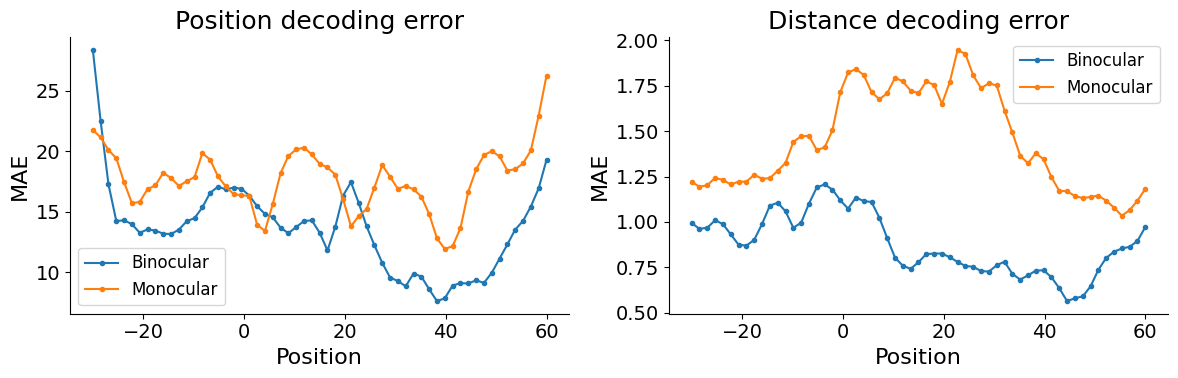

In [78]:
positions = np.squeeze(R.angle_range)

X_monocular, distances_monocular = obtain_neural_data(reliable_cells, distance=None, monocular=True)
X_binocular, distances_binocular = obtain_neural_data(reliable_cells, distance=None, monocular=False)

# Run decoders
pred_bino, actual_bino, _, _ = decode_joint(X_binocular, positions, distances)
pred_mono, actual_mono, _, _ = decode_joint(X_monocular, positions, distances)

# Plot together
results = {
    'Binocular': (pred_bino, actual_bino),
    'Monocular': (pred_mono, actual_mono),
}
plot_errors_by_position(results)

In [208]:
def decode_distance_by_position(X, positions, distances, window=20):
    """
    Train separate distance decoder for each position.
    Uses average of neighboring positions (smoothing).
    
    X: (n_trials, n_positions, n_cells)
    positions: (n_positions,)
    distances: (n_trials,)
    window: number of positions to average (centered)
    
    Returns: r2_per_pos, mae_per_pos
    """
    n_trials, n_positions, n_cells = X.shape
    half = window // 2
    
    r2_per_pos = []
    mae_per_pos = []
    
    for i in range(n_positions):
        # Get indices for window (handle edges)
        start = max(0, i - half)
        end = min(n_positions, i + half + 1)
        
        X_pos = X[:, start:end, :].mean(axis=1)  # (n_trials, n_cells)
        y = distances
        
        # Leave-one-out CV
        predictions = np.zeros(n_trials)
        for test_idx in range(n_trials):
            train_idx = np.arange(n_trials) != test_idx
            model = Ridge(alpha=1.0)
            model.fit(X_pos[train_idx], y[train_idx])
            predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
        
        r2 = 1 - np.sum((y - predictions)**2) / np.sum((y - y.mean())**2)
        mae = np.mean(np.abs(y - predictions))
        
        r2_per_pos.append(r2)
        mae_per_pos.append(mae)
    
    return np.array(r2_per_pos), np.array(mae_per_pos)


def plot_distance_decoding_by_position(results_dict, positions):
    """
    results_dict: {
        'Binocular': (r2_per_pos, mae_per_pos),
        'Monocular': (r2_per_pos, mae_per_pos),
    }
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    for label, (r2_per_pos, mae_per_pos) in results_dict.items():
        axes[0].plot(positions, r2_per_pos, 'o-', label=label, markersize=4)
        axes[1].plot(positions, mae_per_pos, 'o-', label=label, markersize=4)
    
    axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.5)
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('R²')
    axes[0].set_title('Distance decoding R²')
    axes[0].legend()
    
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('MAE')
    axes[1].set_title('Distance decoding MAE')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

Trials: 48, Positions: 59, Neurons: 249
Trials: 48, Positions: 59, Neurons: 249


C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3694408790.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3694408790.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3694408790.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation

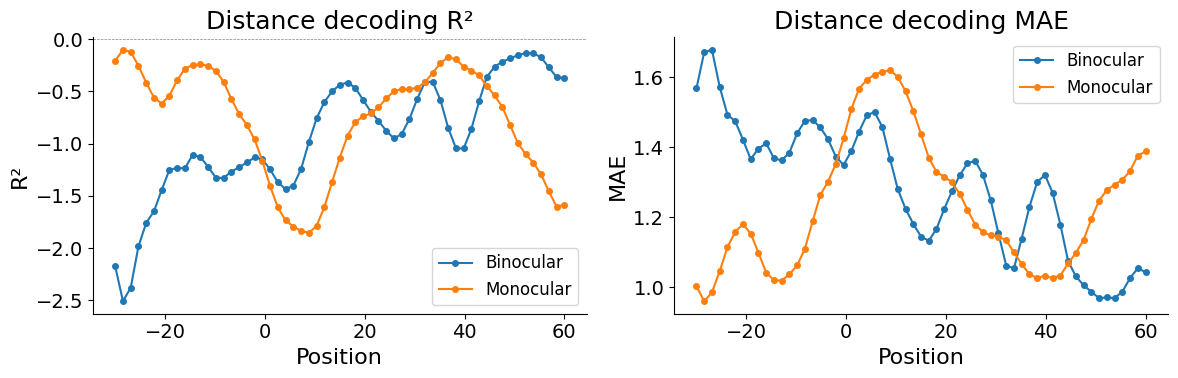

In [212]:
positions = np.squeeze(R.angle_range)
X_monocular, distances_monocular = obtain_neural_data(reliable_cells, distance=None, monocular=True)
X_binocular, distances_binocular = obtain_neural_data(reliable_cells, distance=None, monocular=False)

r2_bino, mae_bino = decode_distance_by_position(X_binocular, positions, distances)
r2_mono, mae_mono = decode_distance_by_position(X_monocular, positions, distances)

results = {
    'Binocular': (r2_bino, mae_bino),
    'Monocular': (r2_mono, mae_mono),
}
plot_distance_decoding_by_position(results, positions)

In [205]:
from sklearn.metrics import confusion_matrix

def decode_distance_by_position(X, positions, distances, window=10):
    """
    Train separate distance decoder for each position.
    
    X: (n_trials, n_positions, n_cells)
    positions: (n_positions,)
    distances: (n_trials,)
    window: number of positions to average (centered)
    
    Returns: r2_per_pos, mae_per_pos, predictions_all, actual_all
    """
    n_trials, n_positions, n_cells = X.shape
    half = window // 2
    
    r2_per_pos = []
    mae_per_pos = []
    predictions_all = []  # store all predictions
    actual_all = []       # store all actual values
    
    for i in range(n_positions):
        start = max(0, i - half)
        end = min(n_positions, i + half + 1)
        
        X_pos = X[:, start:end, :].mean(axis=1)
        y = distances
        
        predictions = np.zeros(n_trials)
        for test_idx in range(n_trials):
            train_idx = np.arange(n_trials) != test_idx
            model = Ridge(alpha=1.0)
            model.fit(X_pos[train_idx], y[train_idx])
            predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
        
        r2 = 1 - np.sum((y - predictions)**2) / np.sum((y - y.mean())**2)
        mae = np.mean(np.abs(y - predictions))
        
        r2_per_pos.append(r2)
        mae_per_pos.append(mae)
        predictions_all.append(predictions)
        actual_all.append(y)
    
    return (np.array(r2_per_pos), np.array(mae_per_pos), 
            np.concatenate(predictions_all), np.concatenate(actual_all))


def plot_distance_decoding_by_position(results_dict, positions, distance_levels):
    """
    results_dict: {
        'Binocular': (r2_per_pos, mae_per_pos, predictions, actual),
        ...
    }
    distance_levels: unique distance values, e.g. [1, 2, 3, 4]
    """
    n_conditions = len(results_dict)
    fig, axes = plt.subplots(2, n_conditions + 1, figsize=(5 * (n_conditions + 1), 8))
    
    # Top row: R² and MAE curves
    for label, (r2_per_pos, mae_per_pos, _, _) in results_dict.items():
        axes[0, 0].plot(positions, r2_per_pos, 'o-', label=label, markersize=4)
        axes[0, 1].plot(positions, mae_per_pos, 'o-', label=label, markersize=4)
    
    axes[0, 0].axhline(0, color='gray', linestyle='--', linewidth=0.5)
    axes[0, 0].set_xlabel('Position')
    axes[0, 0].set_ylabel('R²')
    axes[0, 0].set_title('Distance decoding R²')
    axes[0, 0].legend()
    
    axes[0, 1].set_xlabel('Position')
    axes[0, 1].set_ylabel('MAE')
    axes[0, 1].set_title('Distance decoding MAE')
    axes[0, 1].legend()
    
    # Hide unused top-right panels
    for i in range(2, n_conditions + 1):
        axes[0, i].axis('off')
    
    # Bottom row: confusion matrices
    for idx, (label, (_, _, predictions, actual)) in enumerate(results_dict.items()):
        # Round predictions to nearest valid distance
        pred_rounded = np.array([distance_levels[np.argmin(np.abs(distance_levels - p))] 
                                  for p in predictions])
        
        cm = confusion_matrix(actual, pred_rounded, labels=distance_levels)
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)  # normalize by row
        
        im = axes[1, idx].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
        axes[1, idx].set_xticks(range(len(distance_levels)))
        axes[1, idx].set_yticks(range(len(distance_levels)))
        axes[1, idx].set_xticklabels(distance_levels)
        axes[1, idx].set_yticklabels(distance_levels)
        axes[1, idx].set_xlabel('Predicted')
        axes[1, idx].set_ylabel('Actual')
        axes[1, idx].set_title(f'{label} confusion matrix')
        plt.colorbar(im, ax=axes[1, idx])
    
    # Hide unused bottom panels
    for i in range(n_conditions, n_conditions + 1):
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.show()

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3083140722.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3083140722.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predictions[test_idx] = model.predict(X_pos[test_idx:test_idx+1])
C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_11660\3083140722.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation

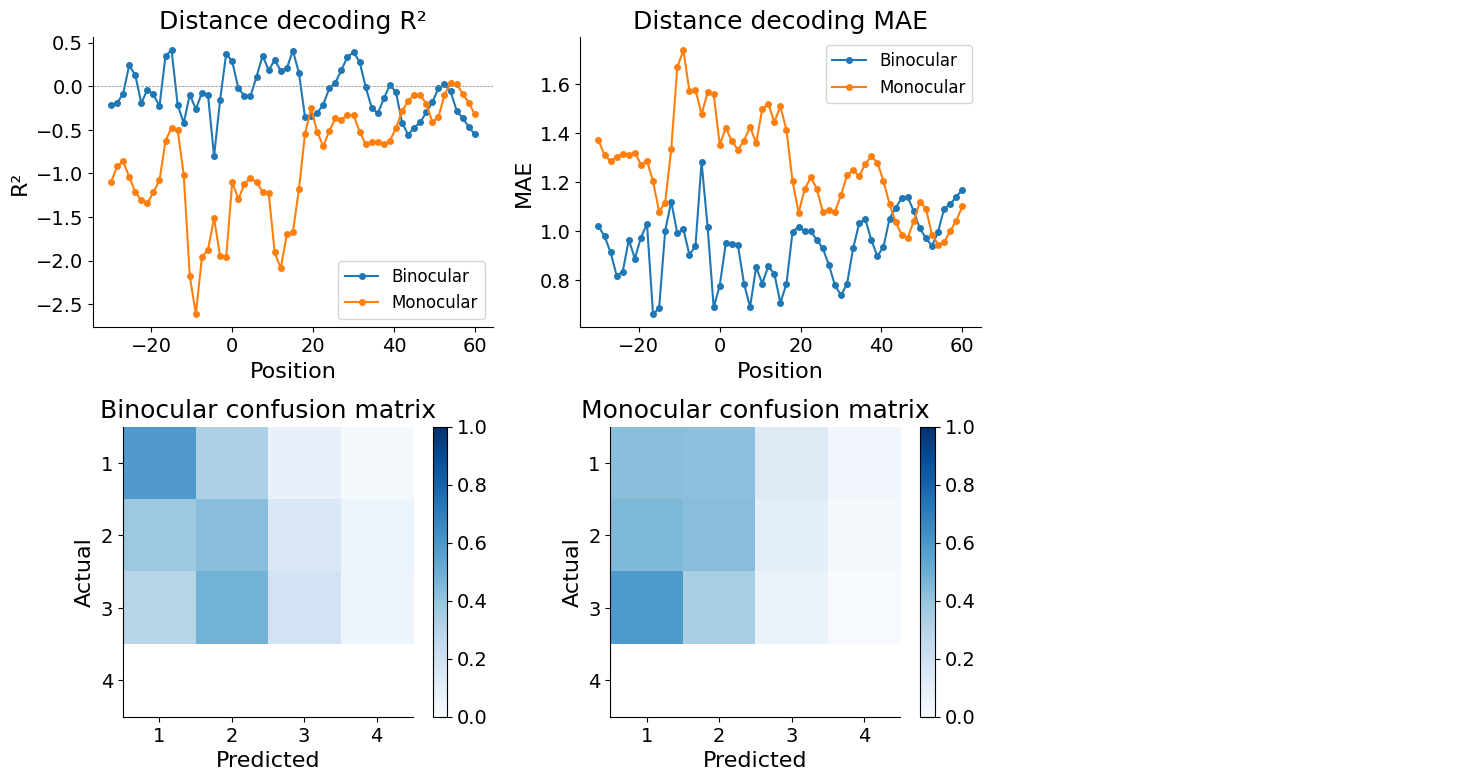

In [206]:
from sklearn.metrics import confusion_matrix

distance_levels = np.array([1, 2, 3, 4])  # your 4 levels

r2_bino, mae_bino, pred_bino, actual_bino = decode_distance_by_position(X_binocular, positions, distances, window=5)
r2_mono, mae_mono, pred_mono, actual_mono = decode_distance_by_position(X_monocular, positions, distances, window=5)

results = {
    'Binocular': (r2_bino, mae_bino, pred_bino, actual_bino),
    'Monocular': (r2_mono, mae_mono, pred_mono, actual_mono),
}
plot_distance_decoding_by_position(results, positions, distance_levels)